Connected to Python 3.13.2

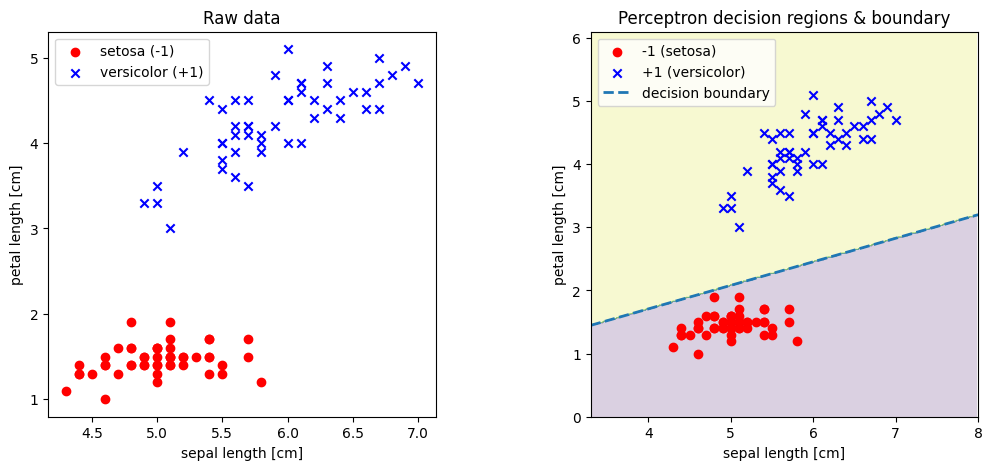

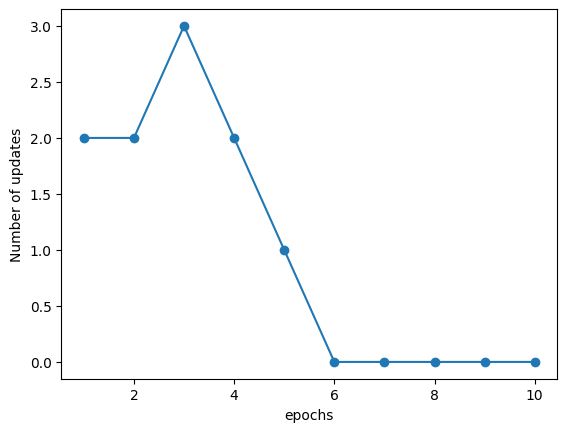

In [ ]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

def plot_decision_boundary(ax, X, y, clf, step=0.02):
    """
    畫出感知器的分類分區(背景) + 資料點 + 決策直線
    clf 需有屬性 w_ = [b, w1, w2]，且 predict(X) 可用
    """
    # 1) 背景分區
    x1_min, x1_max = X[:, 0].min() - 1.0, X[:, 0].max() + 1.0
    x2_min, x2_max = X[:, 1].min() - 1.0, X[:, 1].max() + 1.0
    xx1, xx2 = np.meshgrid(np.arange(x1_min, x1_max, step),
                           np.arange(x2_min, x2_max, step))
    grid = np.c_[xx1.ravel(), xx2.ravel()]
    Z = clf.predict(grid).reshape(xx1.shape)
    ax.contourf(xx1, xx2, Z, alpha=0.2)  # 分類背景

    # 2) 資料點
    ax.scatter(X[y==-1, 0], X[y==-1, 1], c='r', marker='o', label='-1 (setosa)')
    ax.scatter(X[y== 1, 0], X[y== 1, 1], c='b', marker='x', label='+1 (versicolor)')

    # 3) 決策邊界直線：w1*x1 + w2*x2 + b = 0 → x2 = -(w1/w2)*x1 - b/w2
    b, w1, w2 = clf.w_[0], clf.w_[1], clf.w_[2]
    # 若 w2 很小，避免除以 0：改畫 x = 常數 的直線
    if abs(w2) > 1e-12:
        xs = np.linspace(x1_min, x1_max, 200)
        ys = -(w1/w2)*xs - b/w2
        ax.plot(xs, ys, linewidth=2, linestyle='--', label='decision boundary')
    else:
        # 直線近乎垂直：w1*x1 + b = 0 → x1 = -b/w1
        x_vertical = -b / (w1 + 1e-12)
        ax.axvline(x_vertical, linewidth=2, linestyle='--', label='decision boundary')

    ax.set_xlim(x1_min, x1_max)
    ax.set_ylim(x2_min, x2_max)
    ax.set_xlabel('sepal length [cm]')
    ax.set_ylabel('petal length [cm]')
    ax.legend(loc='upper left')
    ax.set_title('Perceptron decision regions & boundary')

#
class preceptron(object):
    def __init__(self , eta = 0.01 , n_iter = 50 , random_state= 42):
        self.eta = eta
        self.n_iter = n_iter
        self.random_state = random_state
    def fit(self , X ,y):
        #固定種子
        randomGen = np.random.RandomState(self.random_state)
        #
        self.w_ = randomGen.normal(loc=0.0, scale=0.01, size=1 + X.shape[1])
        self.errors_ = []    #紀錄
        
        #每輪跑整個資料及
        for _ in range(self.n_iter):
            errors = 0   #計算本輪多槍本被更新
            #竹樣本更新
            for xi , target in zip (X,y):
                update = self.eta * (target - self.predict(xi))
                self.w_[1:] += update * xi
                self.w_[0]  += update
                errors += int(update != 0.0)
            self.errors_.append(errors)
        return self
    #加權總合 相乘
    def net_input(self, X):
        return np.dot(X, self.w_[1:]) + self.w_[0]
    #感知器的 階躍函數
    def predict(self, X):
        return np.where(self.net_input(X) >= 0.0, 1, -1)        

from sklearn import datasets
import numpy as np

# 載入資料
iris = datasets.load_iris()

# 特徵矩陣 (150筆, 4個特徵)
X = iris.data
y = iris.target


# 取前 100 筆資料（class 0, 1）
X = X[0:100, [0, 2]]  # 第0欄(sepal length)、第2欄(petal length)
y = y[0:100]

# 將標籤轉成 -1 / 1（符合感知器需求）
y = np.where(y == 0, -1, 1)





# 套用Perceptron Learning
ppn = preceptron(eta=0.1, n_iter=10) 
ppn.fit(X, y)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plt.subplots_adjust(wspace=0.4)

# 左圖：原本的資料散點
axes[0].scatter(X[:50, 0], X[:50, 1], color='red', marker='o', label='setosa (-1)')
axes[0].scatter(X[50:100, 0], X[50:100, 1], color='blue', marker='x', label='versicolor (+1)')
axes[0].set_xlabel('sepal length [cm]')
axes[0].set_ylabel('petal length [cm]')
axes[0].legend(loc='upper left')
axes[0].set_title('Raw data')

# 右圖：決策分區 + 邊界 + 點
plot_decision_boundary(axes[1], X, y, ppn)

plt.show()


plt.plot(range(1, len(ppn.errors_) + 1), ppn.errors_, marker='o')
plt.xlabel('epochs')						# 迭代次數
plt.ylabel('Number of updates') # 更新的大小
plt.show()

In [ ]:
import numpy as np

# XOR 資料（用你的標籤規則 -1 / +1）
X = np.array([[0,0],[0,1],[1,0],[1,1]], dtype=float)
y = np.array([-1, 1, 1, -1], dtype=int)

ppn = preceptron(eta=0.1, n_iter=200, random_state=0)
ppn.fit(X, y)

print("最後權重:", ppn.w_)
print("每個 epoch 的更新次數:", ppn.errors_)
print("是否曾經 0 錯誤？", (np.array(ppn.errors_) == 0).any())

最後權重: [ 0.01764052 -0.19599843  0.00978738]
每個 epoch 的更新次數: [3, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4]
是否曾經 0 錯誤？ False
